# Demo: GA vs BPSO vs Random Search

Menjalankan konfigurasi terbaik ketiga algoritma pada satu instance, iterasi per iterasi, dengan seed dan budget yang sama seperti notebook percobaan. Yang ditampilkan:

- kurva konvergensi (gap ke optimum brute-force) yang bergerak
- alokasi dieset ke mesin dari solusi terbaik tiap algoritma, dibanding optimum
- beban tiap mesin terhadap kapasitas
- tabel cost, gap, evaluasi, dan waktu

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
DEMO_DIR = ROOT / "demo"
for folder in (ROOT, DEMO_DIR):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.animation import PillowWriter

from live_demo import Demo

## Parameter

In [2]:
INSTANCE = 19     # 3 | 9 | 13 | 16 | 18 | 19
SEED = None       # None = seed pertama dari master seed di configs/experiment.json
BUDGET = None     # None = max_evaluations dari configs/experiment.json
STEP = 50         # evaluasi per frame animasi
DELAY = 0.05      # jeda antar frame (detik)

## Jalankan Demo

instance 19 dieset, seed 1829338324, optimum brute-force 6,112,960.59


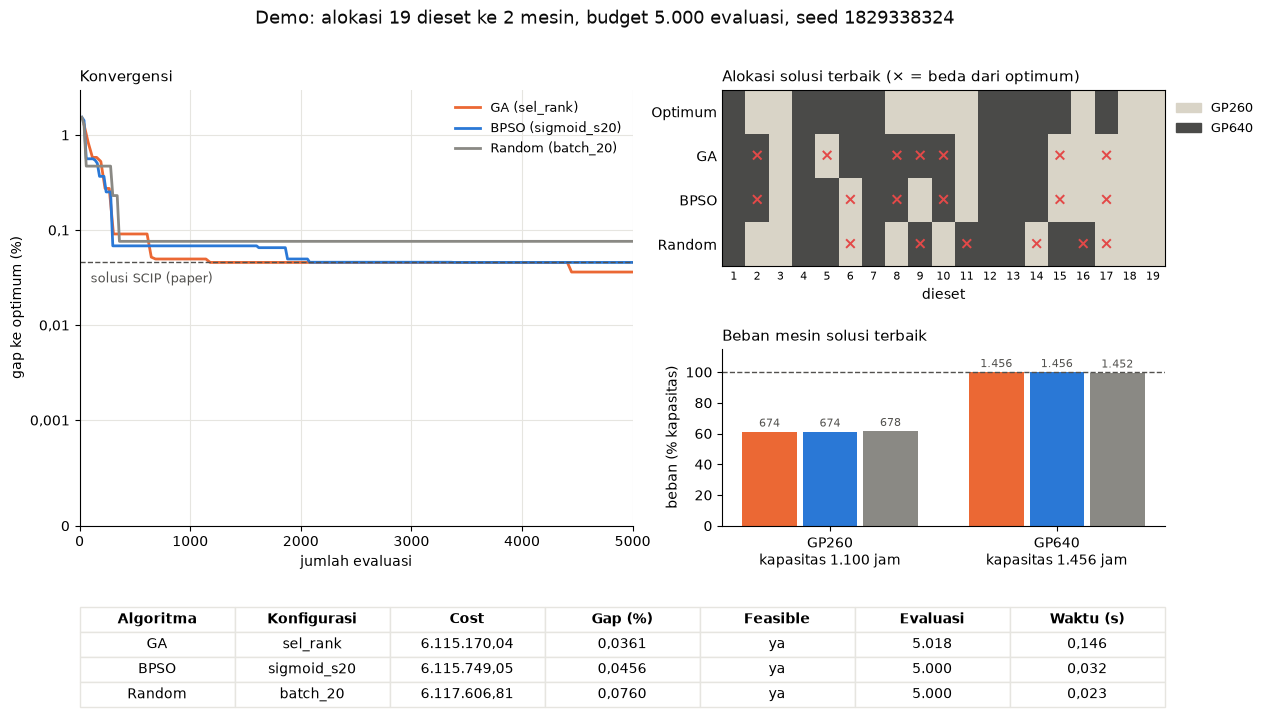

In [3]:
demo = Demo(INSTANCE, seed=SEED, budget=BUDGET, step=STEP)
print(f"instance {INSTANCE} dieset, seed {demo.seed}, optimum brute-force {demo.opt_cost:,.2f}")

handle = display(demo.fig, display_id=True)
plt.close(demo.fig)   # cegah gambar tampil dua kali
for _ in demo.frames():
    handle.update(demo.fig)
    time.sleep(DELAY)

## Hasil Akhir

Tabel diurutkan dari gap terkecil. Baris terakhir adalah solusi SCIP dari paper sebagai pembanding. Dua tabel di bawahnya adalah konteks dari 30 run percobaan untuk instance yang sama (`exp_results/tables/comparison/`): statistik gap dan uji Mann-Whitney U antar algoritma.

In [4]:
display(demo.result_table())

context = demo.context_tables()
if context is None:
    print("tabel konteks belum ada, jalankan experiments/comparison.ipynb terlebih dahulu")
else:
    gap_stats, tests = context
    display(gap_stats)
    display(tests)

,Algoritma,Konfigurasi,Cost,Selisih ke optimum,Gap (%),Dieset beda dari optimum,Feasible,Evaluasi sampai terbaik,Waktu (s)
Peringkat,,,,,,,,,
1,GA,sel_rank,"6.115.170,04","2.209,45","0,0361",7 dari 19,ya,4.448,"0,146"
2,BPSO,sigmoid_s20,"6.115.749,05","2.788,46","0,0456",6 dari 19,ya,3.380,"0,032"
3,Random,batch_20,"6.117.606,81","4.646,22","0,0760",6 dari 19,ya,360,"0,023"
-,Solusi SCIP (paper),-,"6.115.761,14","2.800,55","0,0458",-,ya,-,-


,algorithm,best,mean,std,worst,n_runs
15,genetic,0.0000,0.0338,0.0161,0.0737,30
16,random_search,0.0023,0.0948,0.0439,0.2063,30
17,swarm,0.0000,0.0308,0.0189,0.0737,30


,algorithm_a,algorithm_b,median_a,median_b,p_value,significant,better
15,genetic,random_search,0.0332,0.0882,0.0000,True,genetic
16,genetic,swarm,0.0332,0.0302,0.6657,False,-
17,random_search,swarm,0.0882,0.0302,0.0000,True,swarm


## Simpan Animasi (opsional)

Untuk bahan video demo cadangan.

In [5]:
out = DEMO_DIR / f"demo_{INSTANCE}_diesets.gif"

recording = Demo(INSTANCE, seed=SEED, budget=BUDGET, step=STEP)
writer = PillowWriter(fps=round(1 / DELAY))
with writer.saving(recording.fig, out, dpi=90):
    for _ in recording.frames():
        writer.grab_frame()
plt.close(recording.fig)
print("disimpan ke", out.relative_to(ROOT))

disimpan ke demo/demo_19_diesets.gif
